### 1) Import Libraries

# Biomedical Insurance Cost Predictor (Traditional Machine Learning) - Insurance dataset

In [ ]:
# Import libraries and modules

# ---------- path setup ----------
import sys
from pathlib import Path

PROJECT_ROOT = Path().resolve().parent.parent.parent
sys.path.insert(0, str(PROJECT_ROOT / "Notebooks"))
DATA_DIR = PROJECT_ROOT / "Data/insurance_dataset"
REG_DIR = PROJECT_ROOT / "Outputs/reg_ins_ml"; REG_DIR.mkdir(parents=True, exist_ok=True)
REG_DIR_FIG = PROJECT_ROOT / "Outputs/reg_ins_ml_fig"; REG_DIR_FIG.mkdir(parents=True, exist_ok=True)


#----- Tools, visualizers -----
from utils import *
import pandas as pd
from scipy.stats import loguniform, randint, uniform
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import joblib

#----- Preprocessing -----
from sklearn.model_selection import cross_validate, KFold, cross_val_predict, cross_val_score, RepeatedKFold, RandomizedSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.base import clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import make_scorer, mean_squared_error, mean_absolute_error, r2_score, root_mean_squared_error

#----- Models -----
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso,\
      ElasticNet, RANSACRegressor, HuberRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor,\
      AdaBoostRegressor, ExtraTreesRegressor

#----- Variables -----
RANDOM_STATE = 42



### 2) Load Data

In [2]:
# Load train set
#---------------
data = pd.read_csv(DATA_DIR / "insurance_train_set.csv")
test = pd.read_csv(DATA_DIR / "insurance_test_set.csv")

data.shape, test.shape

((1137, 7), (201, 7))

#### About handling invalid values
Since the dataset at hand is already clean and there are no missing & invalid values, We do not perform this stage in this notebook.

### 3) Define feature columns and target 
> Target: charges

In [3]:
"""
Separate features and target for the regression task.

- Target: `charges`
- Features: all columns except `charges`

"""

# -------------------------------------
# charges as the target
# -------------------------------------

# ---------- DATA ---------

# Separate features and labels cols
X_TRAIN = data.drop(columns=['charges']) # Features
y_train = data['charges'] # Labels


# ---------- TEST ---------

# Separate features and labels cols
X_TEST = test.drop(columns=['charges']) # Features
y_test = test['charges'] # Labels


# Display shapes
print("----- DONE -----", end='\n\n')
print(f"Shapes:\n\nX_TRAIN: {X_TRAIN.shape} | y_train: {y_train.shape}")
print(f"X_TEST: {X_TEST.shape} | y_test: {y_test.shape}")


----- DONE -----

Shapes:

X_TRAIN: (1137, 6) | y_train: (1137,)
X_TEST: (201, 6) | y_test: (201,)


In [4]:
print("smoker:", X_TRAIN['smoker'].unique())
print("sex:", X_TRAIN['sex'].unique())
print("region:", X_TRAIN['region'].unique())

smoker: <ArrowStringArray>
['yes', 'no']
Length: 2, dtype: str
sex: <ArrowStringArray>
['male', 'female']
Length: 2, dtype: str
region: <ArrowStringArray>
['northwest', 'southeast', 'southwest', 'northeast']
Length: 4, dtype: str


### 4) Core Feature Engineering

#### 1- Feature columns (except target)

In [5]:

# Experiment 1
def smoking_interaction_features(X):
    # Make a copy of X
    x = X.copy()

    # Binarize smoker col - Temporary
    smoker_num = x['smoker'].map({'no': 0, 'yes': 1}) 

    # Build obesity feature that's needed for high_risk feature - temporary
    x['obesity'] = np.where(x['bmi'] >= 30, 1, 0)

    # Build smoker related features
    x['bmi_smoker'] = x['bmi'] * smoker_num
    x['age_smoker'] = x['age'] * smoker_num
    x['high_risk'] = x['obesity'] * smoker_num

    # Drop obesity col
    x.drop(columns=['obesity'], inplace=True)

    return x

# Expriment 2
def bmi_age_related_features(X):
    # Make a copy of X
    x = X.copy()

    # Build bmi/age related features
    x['bmi_age'] = x['age'] * x['bmi']
    x['obesity'] = np.where(x['bmi'] >= 30, 1, 0)
    x['severe_obesity'] = np.where(x['bmi'] >= 35, 1, 0)

    return x

# Experiment 3
def all_eng_featured_combined(X):
    # Make a copy of X
    x = X.copy()

    # Binarize smoker col - Temporary
    smoker_num = x['smoker'].map({'no': 0, 'yes': 1})

    # Build bmi/age related features
    x['bmi_age'] = x['age'] * x['bmi']
    x['obesity'] = np.where(x['bmi'] >= 30, 1, 0)
    x['severe_obesity'] = np.where(x['bmi'] >= 35, 1, 0)

    # Build smoker related features
    x['bmi_smoker'] = x['bmi'] * smoker_num
    x['age_smoker'] = x['age'] * smoker_num
    x['high_risk'] = x['obesity'] * smoker_num

    return x


# Apply smoker related eng
x_smoker_train = smoking_interaction_features(X_TRAIN)
x_smoker_test = smoking_interaction_features(X_TEST)

# Apply bmi/age related eng
x_bmi_age_train = bmi_age_related_features(X_TRAIN)
x_bmi_age_test = bmi_age_related_features(X_TEST)

# Apply all features eng
x_all_train = all_eng_featured_combined(X_TRAIN)
x_all_test = all_eng_featured_combined(X_TEST)


print("----- Feature Engineering Done -----")


----- Feature Engineering Done -----


In [6]:
# Check basekine
X_TRAIN.head(5)

,age,sex,bmi,children,smoker,region
0,52,male,27.360,0,yes,northwest
1,30,male,44.220,2,no,southeast
2,19,male,27.265,2,no,northwest
3,20,female,26.840,1,yes,southeast
4,27,female,24.750,0,yes,southeast


In [7]:
# Check ex1
x_smoker_train.head(5)

,age,sex,bmi,children,smoker,region,bmi_smoker,age_smoker,high_risk
0,52,male,27.360,0,yes,northwest,27.36,52,0
1,30,male,44.220,2,no,southeast,0.00,0,0
2,19,male,27.265,2,no,northwest,0.00,0,0
3,20,female,26.840,1,yes,southeast,26.84,20,0
4,27,female,24.750,0,yes,southeast,24.75,27,0


In [8]:
# Check ex2
x_bmi_age_train.head(5)

,age,sex,bmi,children,smoker,region,bmi_age,obesity,severe_obesity
0,52,male,27.360,0,yes,northwest,1422.720,0,0
1,30,male,44.220,2,no,southeast,1326.600,1,1
2,19,male,27.265,2,no,northwest,518.035,0,0
3,20,female,26.840,1,yes,southeast,536.800,0,0
4,27,female,24.750,0,yes,southeast,668.250,0,0


In [9]:
# Check ex3
x_all_train.head(5)

,age,sex,bmi,children,smoker,region,bmi_age,obesity,severe_obesity,bmi_smoker,age_smoker,high_risk
0,52,male,27.360,0,yes,northwest,1422.720,0,0,27.36,52,0
1,30,male,44.220,2,no,southeast,1326.600,1,1,0.00,0,0
2,19,male,27.265,2,no,northwest,518.035,0,0,0.00,0,0
3,20,female,26.840,1,yes,southeast,536.800,0,0,26.84,20,0
4,27,female,24.750,0,yes,southeast,668.250,0,0,24.75,27,0


##### -  A quick sanity check and EDA for new features

In [10]:
all_new_num = ['bmi_smoker', 'age_smoker', 'bmi_age']

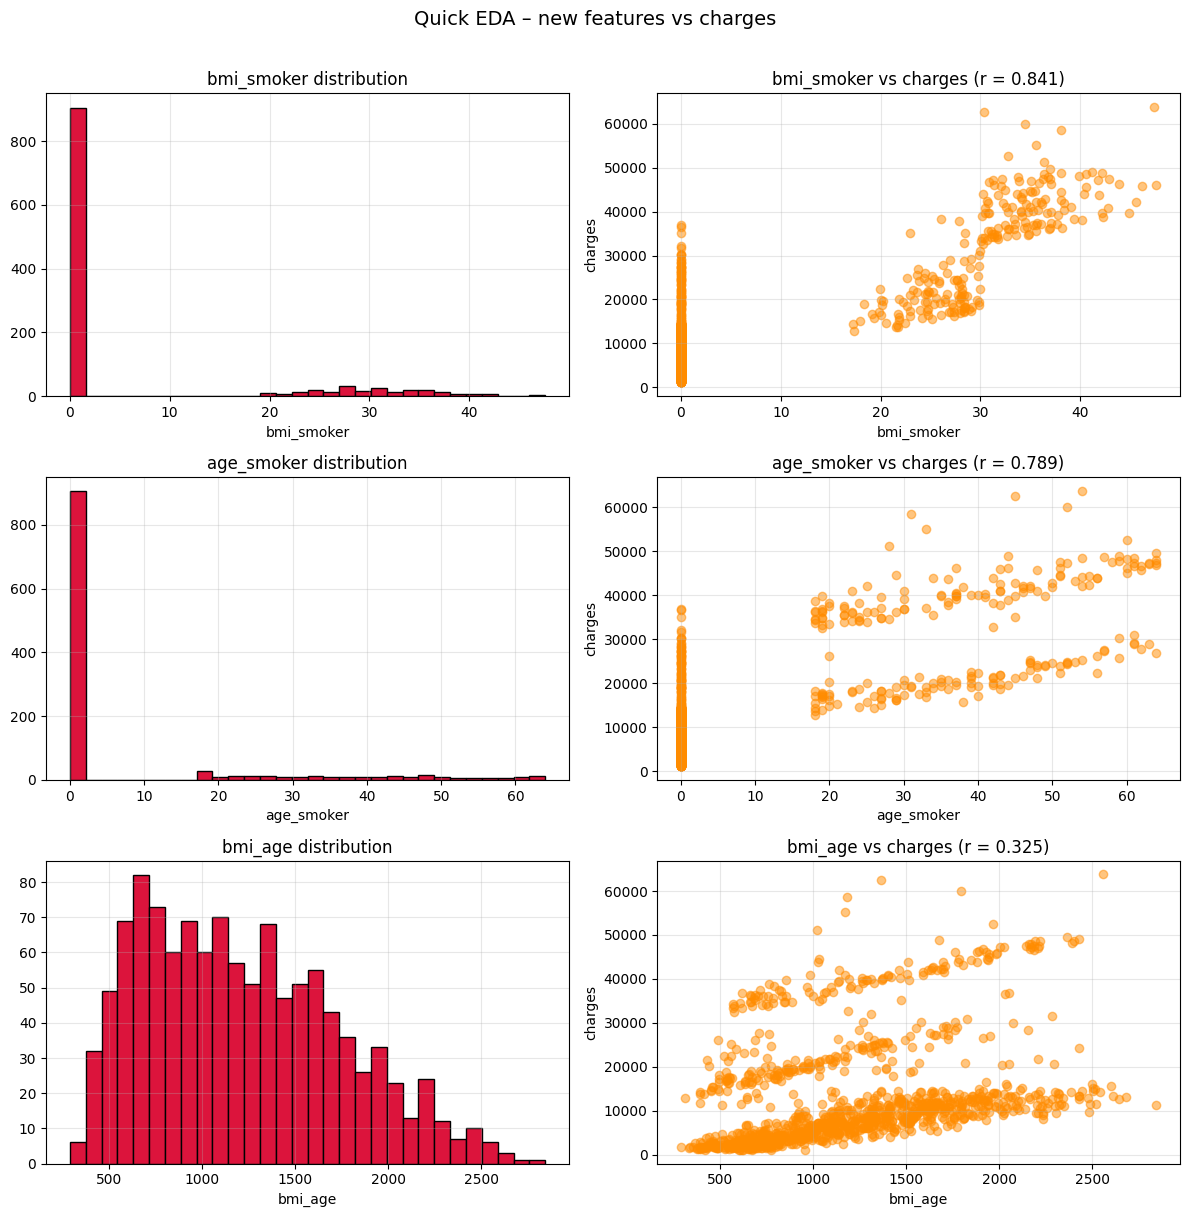

In [11]:
# Quick EDA on the numeric features
# ---------------------------------------------
def plot_features_eda(X, y, features, target_name, hist_c, scat_c, ncols=2):
    """
    For each feature in `features`, create a row with two subplots:
    histogram of the feature (left) and scatter vs target (right).
    """
    nrows = len(features)
    fig, axes = plt.subplots(nrows, ncols, figsize=(12, 4 * nrows))
    
    # Make sure axes is 2D even for a single row
    if nrows == 1:
        axes = axes.reshape(1, -1)
    
    for i, feat in enumerate(features):
        r, _ = stats.pearsonr(X[feat], y)
        
        # Histogram
        axes[i, 0].hist(X[feat], bins=30, color=hist_c, edgecolor='k')
        axes[i, 0].set_title(f'{feat} distribution')
        axes[i, 0].set_xlabel(feat)
        axes[i, 0].grid(alpha=0.3)
        
        # Scatter
        axes[i, 1].scatter(X[feat], y, alpha=0.5, color=scat_c)
        axes[i, 1].set_title(f'{feat} vs {target_name} (r = {r:.3f})')
        axes[i, 1].set_xlabel(feat)
        axes[i, 1].set_ylabel(target_name)
        axes[i, 1].grid(alpha=0.3)
    
    plt.suptitle(f'Quick EDA – new features vs {target_name}', fontsize=14, y=1.01)
    plt.tight_layout()
    plt.show()


plot_features_eda(x_all_train, y_train, all_new_num,
                  'charges', 'crimson', 'darkorange')



In [12]:
all_new_cat = ['obesity', 'severe_obesity', 'high_risk']

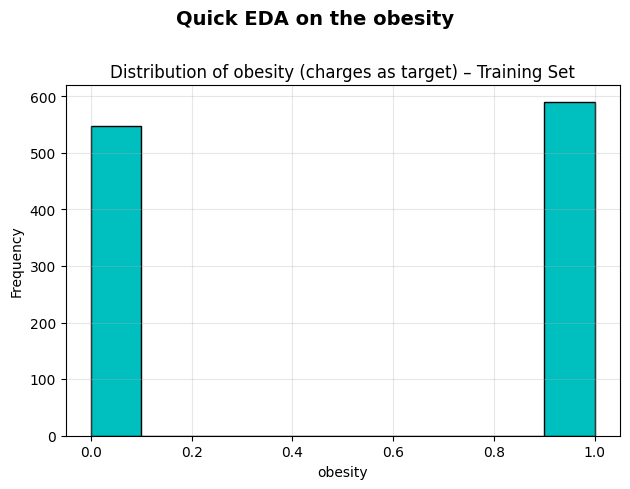

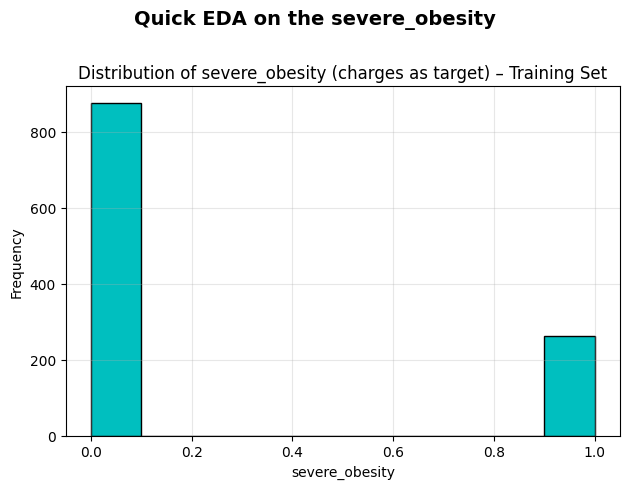

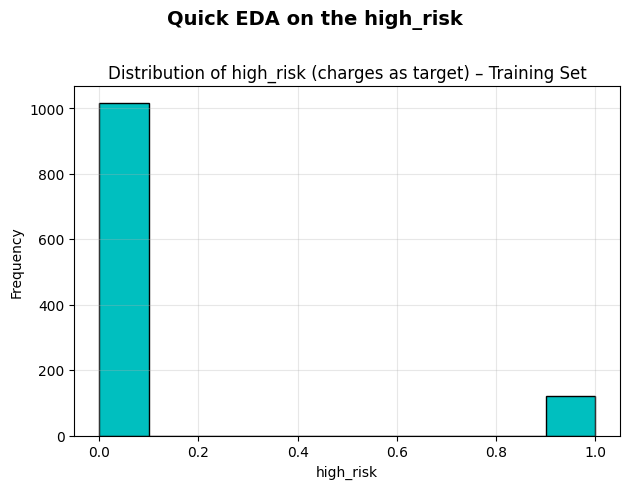

In [13]:
def plot_cat_dis(X, feat):
    # Histogram of new cat features (training set)
    X[feat].hist(color='c', edgecolor='k')
    plt.title(f'Distribution of {feat} (charges as target) – Training Set')
    plt.xlabel(feat)
    plt.ylabel('Frequency')
    plt.grid(alpha=0.3)


    plt.suptitle(f"Quick EDA on the {feat}", fontsize=14, weight='bold' ,y=1.01)
    plt.tight_layout()
    plt.show()


for f in all_new_cat:
    plot_cat_dis(x_all_train, f)

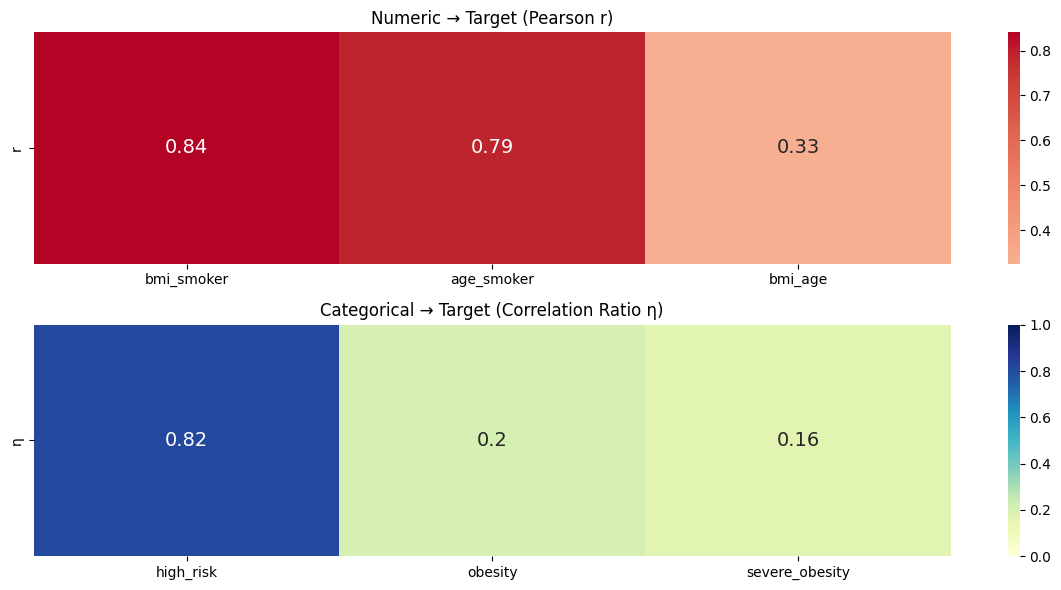

In [15]:
full_train_ana = x_all_train.copy()
full_train_ana['charges'] = y_train.values

# Now pass them to the analyzer
analyzer_all = CorrelationAnalyzer(
    data=full_train_ana,
    target_type='numeric',
    num_cols=all_new_num,
    cat_cols=all_new_cat,
    target_col='charges'
)

analyzer_all.plot_feature_numeric_target(14)

#### 2- Target column
- We'll apply log-transformer on the target to address it being right-skewed. 
- The difference of applying this technique is analyzed and showcased in the `EDA notebook`. 

In [16]:
# Raw targets
y_train_raw = y_train.values
y_test_raw = y_test.values

# Log targets
y_train_log = np.log1p(y_train.values)
y_test_log = np.log1p(y_test.values)

### 5) Core of preprocessing and handling data


In [17]:
"""
"Children was treated as a numerical count variable,
 while sex and Smoking were treated as a binary categorical variable and
 region was encoded using one-hot encoding."
"""

# =====================================================
# Feature Groups
# =====================================================

# ----- Baseline -----

baseline_num_features = ['age', 'bmi', 'children']
baseline_bin_features = ['sex', 'smoker']
baseline_nom_features = ['region']


# ----- Smoker Engineering -----

smoker_num_features = baseline_num_features + ['bmi_smoker', 'age_smoker']
smoker_bin_features = baseline_bin_features + ['high_risk']


# ----- BMI / Age Engineering -----

bmi_age_num_features = baseline_num_features + ['bmi_age']
bmi_age_bin_features = baseline_bin_features + ['obesity', 'severe_obesity']


# ----- All Engineered Features -----

all_eng_num_features = baseline_num_features + ['bmi_age', 'bmi_smoker', 'age_smoker']
all_eng_bin_features = baseline_bin_features + ['obesity', 'severe_obesity', 'high_risk']


# Pipelines
#----------------

# Continuous numeric feat
con_num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])


# Binary feat
bin_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    (
        "encoder",
        OrdinalEncoder(
            handle_unknown="use_encoded_value",
            unknown_value=-1
        )
    )
])

# Nominal feat
nom_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    (
        "encoder",
        OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        )
    )
])


# Combine all Pipelines to build the full preprocessors
#------------------------------------------------------

# --- Baseline ---
preprocessor_baseline = ColumnTransformer([
    ("num", con_num_pipeline, baseline_num_features),
    ("bin", bin_pipeline, baseline_bin_features),
    ("nom", nom_pipeline, baseline_nom_features)
])

# --- Smoker eng ---
preprocessor_smoker = ColumnTransformer([
    ("num", con_num_pipeline, smoker_num_features),
    ("bin", bin_pipeline, smoker_bin_features),
    ("nom", nom_pipeline, baseline_nom_features)
])

# --- BMI / Age eng ---
preprocessor_bmi_age = ColumnTransformer([
    ("num", con_num_pipeline, bmi_age_num_features),
    ("bin", bin_pipeline, bmi_age_bin_features),
    ("nom", nom_pipeline, baseline_nom_features)
])

# --- All eng ---
preprocessor_all = ColumnTransformer([
    ("num", con_num_pipeline, all_eng_num_features),
    ("bin", bin_pipeline, all_eng_bin_features),
    ("nom", nom_pipeline, baseline_nom_features)
])


print("----- Preprocessing Pipelines Ready -----")

----- Preprocessing Pipelines Ready -----


####  - Development set and feature sets

In [ ]:
#--------------------------------------------------------
# Development set + feature sets
#--------------------------------------------------------
X_dev_sets = {                                       # name -> (features, preprocessor)
    "Baseline":    (X_TRAIN,         preprocessor_baseline),
    "Smoker Eng":  (x_smoker_train,  preprocessor_smoker),
    "BMI/Age Eng": (x_bmi_age_train, preprocessor_bmi_age),
    "All Eng":     (x_all_train,     preprocessor_all),
}
X_test_sets = {"Baseline": X_TEST, "Smoker Eng": x_smoker_test, "BMI/Age Eng": x_bmi_age_test, "All Eng": x_all_test}
y_dev_raw = y_train_raw                              # dollars; the log target is handled inside the pipeline
print({k: v[0].shape for k, v in X_dev_sets.items()})

{'Baseline': (1137, 6), 'Smoker Eng': (1137, 9), 'BMI/Age Eng': (1137, 9), 'All Eng': (1137, 12)}


### 6) Model Benchmarking

In [ ]:
#--------------------------------------------------------
# Models + benchmark function
#--------------------------------------------------------
models = {
    'AdaBoost Regressor': AdaBoostRegressor(random_state=RANDOM_STATE),
    'Extra Trees Regressor': ExtraTreesRegressor(random_state=RANDOM_STATE),
    'Gradient Boosting Regressor': GradientBoostingRegressor(random_state=RANDOM_STATE),
    'Random Forest Regressor': RandomForestRegressor(random_state=RANDOM_STATE),
    'Elastic Net': ElasticNet(random_state=RANDOM_STATE),
    'RANSAC Regressor': RANSACRegressor(random_state=RANDOM_STATE),
    'Lasso': Lasso(random_state=RANDOM_STATE),
    'Ridge': Ridge(random_state=RANDOM_STATE),
    'Decision Tree Regressor': DecisionTreeRegressor(random_state=RANDOM_STATE),
    'Linear Regression': LinearRegression(),
    'Huber Regressor': HuberRegressor(),
    'K-Neighbors Regressor': KNeighborsRegressor(),
    'SVR': SVR()
}

scoring = {"R2": "r2", "RMSE": "neg_root_mean_squared_error", "MAE": "neg_mean_absolute_error"}
bench_cv = RepeatedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)     # 15 folds

def build(est, prep, log=False):
    pipe = Pipeline([("prep", clone(prep)), ("model", clone(est))])               # preprocessing refit in every fold
    if log:                                                                       # log target, but scored in dollars
        return TransformedTargetRegressor(regressor=pipe, func=np.log1p, inverse_func=np.expm1)
    return pipe

def model_benchmark(models, X, y_raw, prep, log=False):
    rows = []
    for name, est in models.items():
        r = cross_validate(build(est, prep, log), X, y_raw, cv=bench_cv, scoring=scoring, n_jobs=-1)
        rows.append({"Model": name, "R2_mean": r["test_R2"].mean(), "R2_std": r["test_R2"].std(),
                     "RMSE_mean": -r["test_RMSE"].mean(), "MAE_mean": -r["test_MAE"].mean()})
    return pd.DataFrame(rows).sort_values("R2_mean", ascending=False).reset_index(drop=True)

In [20]:
#--------------------------------------------------------
# Benchmark: 4 feature sets x 2 targets (all scores in dollars)
#--------------------------------------------------------
bench = {}
for tgt, log in [("raw", False), ("log", True)]:
    for fs, (X_, prep_) in X_dev_sets.items():
        bench[(fs, tgt)] = model_benchmark(models, X_, y_dev_raw, prep_, log)
        print(fs, tgt, "done")

# same variable names as before, so the display and plot cells below keep working
baseline_results_raw, smoker_results_raw = bench[("Baseline", "raw")], bench[("Smoker Eng", "raw")]
bmi_age_results_raw, all_eng_results_raw = bench[("BMI/Age Eng", "raw")], bench[("All Eng", "raw")]
baseline_results_log, smoker_results_log = bench[("Baseline", "log")], bench[("Smoker Eng", "log")]
bmi_age_results_log, all_eng_results_log = bench[("BMI/Age Eng", "log")], bench[("All Eng", "log")]

pd.concat({f"{k[0]} | {k[1]}": v for k, v in bench.items()}).to_csv(REG_DIR / "reg_ins_benchmark_cv.csv")

Baseline raw done
Smoker Eng raw done
BMI/Age Eng raw done
All Eng raw done
Baseline log done
Smoker Eng log done
BMI/Age Eng log done
All Eng log done


#### - Results on the RAW TARGET for 4 training sets

In [21]:
baseline_results_raw

,Model,R2_mean,R2_std,RMSE_mean,MAE_mean
0,Gradient Boosting Regressor,0.850688,0.023123,4623.394696,2578.279219
1,Random Forest Regressor,0.833180,0.026040,4884.586815,2727.685233
2,Extra Trees Regressor,0.819204,0.029740,5082.331328,2701.362242
3,AdaBoost Regressor,0.816588,0.026606,5119.900076,3945.580881
4,Lasso,0.734538,0.023926,6176.579874,4252.634855
5,Ridge,0.734534,0.023732,6176.989981,4263.923042
6,Linear Regression,0.734511,0.023927,6176.886918,4252.743867
7,Decision Tree Regressor,0.696560,0.046841,6579.466697,3136.309025
8,Huber Regressor,0.657710,0.041260,6995.567093,3508.688119
9,K-Neighbors Regressor,0.621482,0.032722,7383.151474,4393.027901


In [22]:
smoker_results_raw

,Model,R2_mean,R2_std,RMSE_mean,MAE_mean
0,Lasso,0.860922,0.022411,4462.139345,2429.883608
1,Linear Regression,0.860874,0.022409,4462.907269,2430.552813
2,Ridge,0.860874,0.022527,4462.836806,2431.496679
3,Huber Regressor,0.852035,0.025633,4600.834492,1751.276773
4,RANSAC Regressor,0.851422,0.025521,4610.440323,1751.360222
5,Gradient Boosting Regressor,0.847830,0.024279,4666.949930,2625.760217
6,Random Forest Regressor,0.833582,0.025946,4878.457770,2736.779893
7,K-Neighbors Regressor,0.826463,0.023037,4986.507786,2964.288194
8,Extra Trees Regressor,0.822746,0.028767,5032.967270,2635.771704
9,Elastic Net,0.763334,0.026616,5834.252947,4275.100926


In [23]:
bmi_age_results_raw

,Model,R2_mean,R2_std,RMSE_mean,MAE_mean
0,Gradient Boosting Regressor,0.850039,0.023224,4635.438461,2579.366673
1,Random Forest Regressor,0.834047,0.024261,4875.222121,2721.536698
2,Extra Trees Regressor,0.822237,0.024573,5045.397514,2745.901479
3,AdaBoost Regressor,0.803613,0.022479,5306.020016,4212.898810
4,Lasso,0.738883,0.026398,6125.002024,4286.933814
5,Ridge,0.738877,0.026222,6125.388386,4290.322820
6,Linear Regression,0.738793,0.026410,6126.081730,4287.933753
7,Decision Tree Regressor,0.690544,0.043817,6649.466865,3174.409110
8,Huber Regressor,0.662595,0.040498,6945.864629,3497.398762
9,RANSAC Regressor,0.576428,0.049884,7800.020210,3748.209866


In [24]:
all_eng_results_raw

,Model,R2_mean,R2_std,RMSE_mean,MAE_mean
0,Lasso,0.859808,0.022575,4480.258965,2439.935231
1,Ridge,0.859769,0.022790,4480.712253,2441.155572
2,Linear Regression,0.859697,0.022576,4482.057849,2441.612242
3,Huber Regressor,0.852042,0.025714,4600.675046,1752.272740
4,RANSAC Regressor,0.851496,0.025675,4609.190664,1752.075473
5,Gradient Boosting Regressor,0.848680,0.023962,4654.488715,2612.903976
6,Random Forest Regressor,0.833699,0.024601,4878.769653,2727.554735
7,K-Neighbors Regressor,0.833327,0.023047,4885.637413,2816.012574
8,Extra Trees Regressor,0.824454,0.024324,5013.841502,2720.391564
9,Elastic Net,0.768767,0.026038,5766.618830,4212.306562


#### - Results on the LOG TARGET for 4 training sets

In [26]:
baseline_results_log

,Model,R2_mean,R2_std,RMSE_mean,MAE_mean
0,Random Forest Regressor,0.845432,0.025510,4701.362251,2263.603690
1,Gradient Boosting Regressor,0.840389,0.027914,4775.499724,2284.109961
2,AdaBoost Regressor,0.838315,0.022875,4812.454298,3247.172684
3,Extra Trees Regressor,0.835361,0.029980,4849.326234,2277.899725
4,SVR,0.807982,0.027948,5251.274172,2561.582832
5,Decision Tree Regressor,0.706436,0.037008,6484.275816,3088.467711
6,Ridge,0.508803,0.079354,8384.108333,4256.507824
7,K-Neighbors Regressor,0.507363,0.048196,8423.643875,4536.749447
8,Linear Regression,0.500448,0.081766,8454.228586,4278.621758
9,Huber Regressor,0.384800,0.112000,9378.326518,4446.942515


In [27]:
smoker_results_log

,Model,R2_mean,R2_std,RMSE_mean,MAE_mean
0,Random Forest Regressor,0.845637,0.025275,4698.543742,2262.911313
1,SVR,0.845593,0.026774,4705.078554,2136.343484
2,Gradient Boosting Regressor,0.843851,0.027680,4723.939235,2251.391726
3,AdaBoost Regressor,0.838265,0.021088,4813.728812,3270.075934
4,K-Neighbors Regressor,0.837744,0.025243,4820.598931,2572.963723
5,Extra Trees Regressor,0.836610,0.029003,4830.204205,2242.866626
6,Huber Regressor,0.827573,0.028739,4965.364778,2236.573503
7,Linear Regression,0.821569,0.030931,5048.664736,2522.894529
8,RANSAC Regressor,0.810640,0.034096,5198.894201,2463.389450
9,Ridge,0.805470,0.041010,5260.016722,2589.831643


In [28]:
bmi_age_results_log

,Model,R2_mean,R2_std,RMSE_mean,MAE_mean
0,Random Forest Regressor,0.847512,0.023901,4672.586707,2244.600462
1,Gradient Boosting Regressor,0.841938,0.025015,4756.040529,2264.791279
2,Extra Trees Regressor,0.838419,0.026213,4807.817400,2302.883235
3,AdaBoost Regressor,0.833149,0.023725,4892.992120,3367.400975
4,SVR,0.819444,0.025499,5095.245978,2387.580914
5,Decision Tree Regressor,0.706488,0.048202,6469.808979,3050.583272
6,Ridge,0.514222,0.079224,8338.216730,4225.872400
7,Linear Regression,0.505735,0.082723,8408.774004,4238.795373
8,Huber Regressor,0.381617,0.117260,9398.121905,4433.182994
9,K-Neighbors Regressor,0.367371,0.066482,9540.995814,5279.809284


In [29]:
all_eng_results_log

,Model,R2_mean,R2_std,RMSE_mean,MAE_mean
0,Random Forest Regressor,0.846712,0.024611,4683.494221,2257.242073
1,SVR,0.845223,0.026898,4711.240749,2151.641989
2,K-Neighbors Regressor,0.844093,0.024118,4724.702738,2414.654184
3,Gradient Boosting Regressor,0.841910,0.025658,4756.442064,2270.837687
4,Extra Trees Regressor,0.840082,0.025727,4782.937443,2283.989483
5,AdaBoost Regressor,0.836958,0.022149,4835.639895,3296.002843
6,Huber Regressor,0.828981,0.028753,4945.182369,2218.904481
7,Linear Regression,0.821358,0.031066,5051.619931,2525.690346
8,RANSAC Regressor,0.809649,0.042456,5198.406939,2466.931557
9,Ridge,0.805974,0.041290,5251.895521,2594.615566


#### - The results of benchmarking visualized

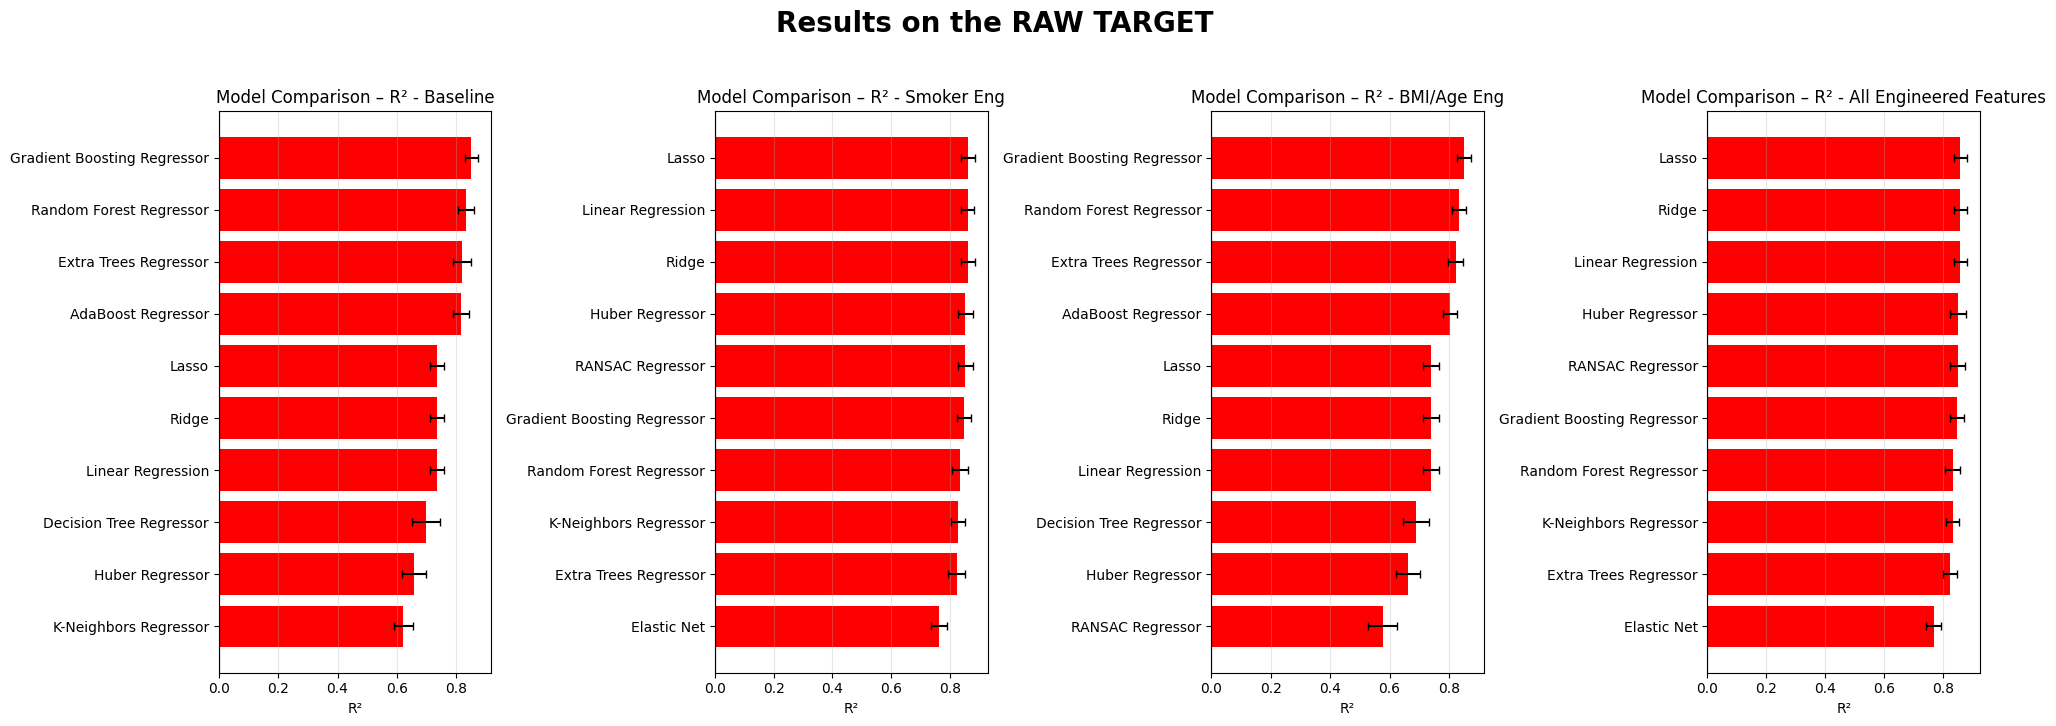

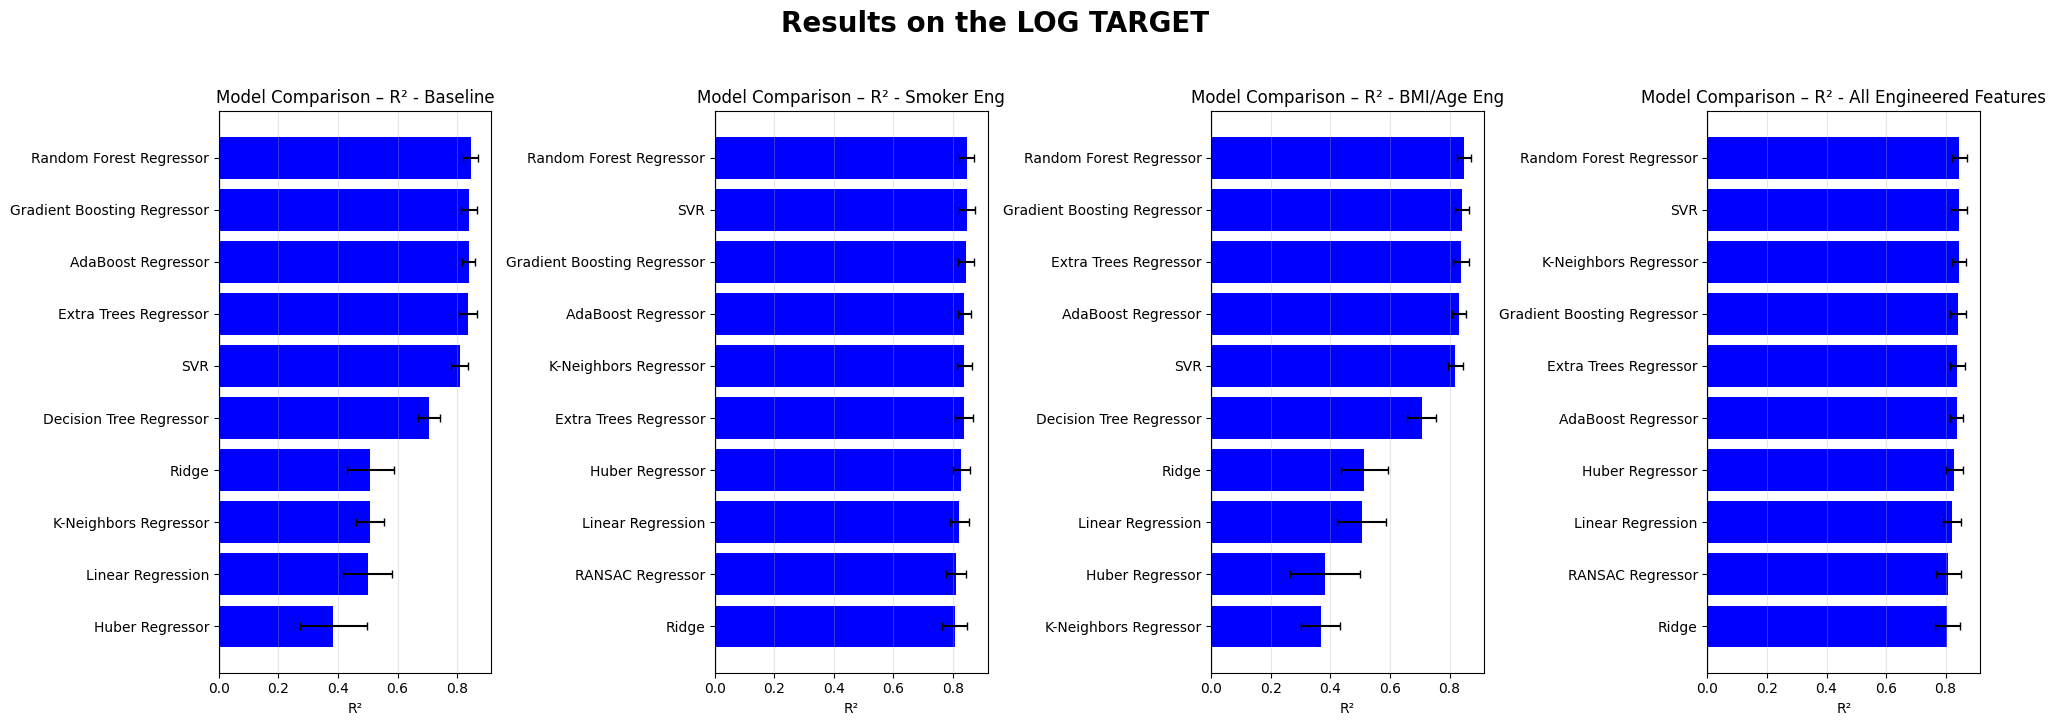

In [30]:
def plot_benchmarking_results(dfs: list, m: str, fe_sets: list, color):

    fig, axs = plt.subplots(1, 4, figsize=(20, 7))

    for i, (df, fe_set) in enumerate(zip(dfs, fe_sets)):
        # Top 10
        df = df.head(10)
        # --- R² ---
        axs[i].barh(df['Model'], df['R2_mean'],
                xerr=df['R2_std'], color=color, capsize=3)
        axs[i].axvline(0, color='black', linewidth=0.8)
        axs[i].set_xlabel('R²')
        axs[i].set_title(f'Model Comparison – R² - {fe_set}')
        axs[i].invert_yaxis()
        axs[i].grid(axis='x', alpha=0.3)

    plt.suptitle(f"Results on the {m}", fontsize=20, y=1.03, weight='bold')

    plt.tight_layout()
    plt.show()


raw_results = [baseline_results_raw, smoker_results_raw, bmi_age_results_raw, all_eng_results_raw]
log_results = [baseline_results_log, smoker_results_log, bmi_age_results_log, all_eng_results_log]

fe_sets = ['Baseline', 'Smoker Eng', 'BMI/Age Eng', 'All Engineered Features']

plot_benchmarking_results(dfs=raw_results, m='RAW TARGET', fe_sets=fe_sets, color='r')
plot_benchmarking_results(dfs=log_results, m='LOG TARGET', fe_sets=fe_sets, color='b')


In [ ]:
#--------------------------------------------------------
# Choice of feature set + target (decided from the repeated-CV table, training data only)
#--------------------------------------------------------
summary = pd.DataFrame([{"Features": k[0], "Target": k[1], "Best model": v.Model[0],
                         "R2 (best)": v.R2_mean[0], "RMSE": v.RMSE_mean[0]} for k, v in bench.items()])
s = summary.sort_values("R2 (best)", ascending=False).round(4)
summary.to_csv(REG_DIR / "reg_ins_feature_target_choice.csv", index=False)

s

,Features,Target,Best model,R2 (best),RMSE
1,Smoker Eng,raw,Lasso,0.8609,4462.1393
3,All Eng,raw,Lasso,0.8598,4480.2590
0,Baseline,raw,Gradient Boosting Regressor,0.8507,4623.3947
2,BMI/Age Eng,raw,Gradient Boosting Regressor,0.8500,4635.4385
6,BMI/Age Eng,log,Random Forest Regressor,0.8475,4672.5867
7,All Eng,log,Random Forest Regressor,0.8467,4683.4942
5,Smoker Eng,log,Random Forest Regressor,0.8456,4698.5437
4,Baseline,log,Random Forest Regressor,0.8454,4701.3623


In [ ]:
BEST_FEATS, BEST_TARGET = "Smoker Eng", "raw"       # check against the top row above; The best of the table above

### 7) Tuning with nested CV

In [35]:
#--------------------------------------------------------
# 7) Nested CV: outer 5x2 folds score the model, inner 3-fold search picks the settings
#--------------------------------------------------------
X_dev, prep_dev = X_dev_sets[BEST_FEATS]; y_dev = y_dev_raw
LOG = (BEST_TARGET == "log"); PFX = "regressor__model__" if LOG else "model__"
outer_cv = RepeatedKFold(n_splits=5, n_repeats=2, random_state=RANDOM_STATE)     # 10 outer folds (same ones the ANN will use)

spaces = {                                           # model, search space
    "Ridge": (Ridge(random_state=RANDOM_STATE), {"alpha": loguniform(1e-3, 1e3)}),
    "Lasso": (Lasso(random_state=RANDOM_STATE, max_iter=20000), {"alpha": loguniform(1e-3, 1e2)}),
    "Elastic Net": (ElasticNet(random_state=RANDOM_STATE, max_iter=20000), {"alpha": loguniform(1e-3, 1e1), "l1_ratio": uniform(0.05, 0.9)}),
    "SVR": (SVR(), {"C": loguniform(1e-1, 1e6), "gamma": loguniform(1e-3, 1), "epsilon": loguniform(1e-3, 1e3)}),
    "K-Neighbors": (KNeighborsRegressor(), {"n_neighbors": randint(3, 31), "weights": ["uniform", "distance"], "p": [1, 2]}),
    "Random Forest": (RandomForestRegressor(random_state=RANDOM_STATE), {"n_estimators": randint(100, 501), "max_depth": [None, 3, 5, 8, 12],
                      "min_samples_leaf": randint(1, 11), "max_features": [1.0, 0.7, 0.5]}),
    "Extra Trees": (ExtraTreesRegressor(random_state=RANDOM_STATE), {"n_estimators": randint(100, 501), "max_depth": [None, 3, 5, 8, 12],
                      "min_samples_leaf": randint(1, 11), "max_features": [1.0, 0.7, 0.5]}),
    "Gradient Boosting": (GradientBoostingRegressor(random_state=RANDOM_STATE), {"n_estimators": randint(100, 501), "learning_rate": loguniform(0.01, 0.3),
                      "max_depth": randint(2, 6), "subsample": uniform(0.6, 0.4), "min_samples_leaf": randint(1, 11)}),
}

def make_search(name):
    est, sp = spaces[name]
    return RandomizedSearchCV(build(est, prep_dev, LOG), {PFX + k: v for k, v in sp.items()}, n_iter=20, scoring="r2",
                              cv=KFold(3, shuffle=True, random_state=1), n_jobs=-1, random_state=RANDOM_STATE)

# Paired comparison (Nadeau-Bengio corrected t-test), same function as the classification notebooks
def nb_paired(a, b):
    d = np.asarray(b) - np.asarray(a); k = len(d)
    se = np.sqrt((1/k + 0.25) * d.var(ddof=1)); t = d.mean() / se
    return d.mean(), 2 * stats.t.sf(abs(t), k - 1)

In [36]:
nested_store, default_store = {}, {}
for name in spaces:
    nested_store[name]  = cross_validate(make_search(name), X_dev, y_dev, cv=outer_cv, scoring=scoring, n_jobs=1)   # tuned (nested)
    default_store[name] = cross_validate(build(spaces[name][0], prep_dev, LOG), X_dev, y_dev, cv=outer_cv, scoring=scoring, n_jobs=-1)  # default settings
    print(f"{name:18s} default R2 {default_store[name]['test_R2'].mean():.4f} | tuned R2 {nested_store[name]['test_R2'].mean():.4f}")

joblib.dump({"nested": nested_store, "default": default_store}, REG_DIR / "reg_ins_ml_cv_stores.joblib")

Ridge              default R2 0.8617 | tuned R2 0.8617
Lasso              default R2 0.8618 | tuned R2 0.8620
Elastic Net        default R2 0.7642 | tuned R2 0.8617
SVR                default R2 -0.0934 | tuned R2 0.8543
K-Neighbors        default R2 0.8276 | tuned R2 0.8399
Random Forest      default R2 0.8352 | tuned R2 0.8573
Extra Trees        default R2 0.8236 | tuned R2 0.8613
Gradient Boosting  default R2 0.8494 | tuned R2 0.8577


['F:\\Desktop\\Projects\\AI-ML-DL\\Medical-Healthcare-Prediction-Framework\\Outputs\\reg_ins_ml\\reg_ins_ml_cv_stores.joblib']

In [38]:
#--------------------------------------------------------
# Tuned vs default, and the best tuned model vs the others (same 10 outer folds)
#--------------------------------------------------------
rows = []
for n in spaces:
    d, t = default_store[n]["test_R2"], nested_store[n]["test_R2"]; diff, p = nb_paired(d, t)
    rows.append({"Model": n, "Default R2": d.mean(), "Tuned R2": t.mean(), "Tuned SD": t.std(), "Diff": diff, "p (corrected)": p,
                 "Tuned RMSE": -nested_store[n]["test_RMSE"].mean(), "Tuned MAE": -nested_store[n]["test_MAE"].mean()})
    
tuning_df = pd.DataFrame(rows).sort_values("Tuned R2", ascending=False).reset_index(drop=True)
tuning_df["significant (Bonferroni)"] = tuning_df["p (corrected)"] < 0.05 / len(spaces)       # 0.05 / 8
tuning_df.round(4).to_csv(REG_DIR / "reg_ins_nested_cv_tuned.csv", index=False)

best_name = tuning_df.loc[0, "Model"]                # rule fixed in advance: best nested-CV mean R2
rows = []
for n in spaces:
    if n != best_name:
        diff, p = nb_paired(nested_store[n]["test_R2"], nested_store[best_name]["test_R2"])
        rows.append({"Compared with": n, f"R2 diff ({best_name} - model)": diff, "p (corrected)": p})

pair_df = pd.DataFrame(rows); pair_df["significant (Bonferroni)"] = pair_df["p (corrected)"] < 0.05 / len(rows)   # 0.05 / 7
pair_df.round(4).to_csv(REG_DIR / "reg_ins_paired.csv", index=False)

In [40]:
tuning_df.round(4)

,Model,Default R2,Tuned R2,Tuned SD,Diff,p (corrected),Tuned RMSE,Tuned MAE,significant (Bonferroni)
0,Lasso,0.8618,0.8620,0.0228,0.0002,0.5162,4452.2200,2428.3392,False
1,Ridge,0.8617,0.8617,0.0231,0.0000,0.8894,4456.1602,2431.0940,False
2,Elastic Net,0.7642,0.8617,0.0231,0.0975,0.0000,4456.3495,2431.7190,True
3,Extra Trees,0.8236,0.8613,0.0226,0.0377,0.0116,4465.3740,2474.7860,False
4,Gradient Boosting,0.8494,0.8577,0.0238,0.0083,0.0511,4521.9845,2513.6617,False
5,Random Forest,0.8352,0.8573,0.0240,0.0220,0.0126,4527.8863,2555.8943,False
6,SVR,-0.0934,0.8543,0.0271,0.9477,0.0000,4571.2670,1363.5351,True
7,K-Neighbors,0.8276,0.8399,0.0266,0.0123,0.1106,4796.5210,2739.8571,False


In [42]:
print("Selected:", best_name); pair_df.round(4)

Selected: Lasso


,Compared with,R2 diff (Lasso - model),p (corrected),significant (Bonferroni)
0,Ridge,0.0003,0.5040,False
1,Elastic Net,0.0003,0.4734,False
2,SVR,0.0077,0.0450,False
3,K-Neighbors,0.0221,0.0067,True
4,Random Forest,0.0047,0.0434,False
5,Extra Trees,0.0007,0.7745,False
6,Gradient Boosting,0.0043,0.0590,False


### 8) Final model and the single test evaluation

In [ ]:
#--------------------------------------------------------
# 8) Final model: search on the whole development set, ONE test evaluation, bootstrap CIs
#--------------------------------------------------------
final_search = make_search(best_name).fit(X_dev, y_dev)
final_ml = final_search.best_estimator_              # already refit on all development data
print("Best settings:", {k.replace(PFX, ""): v for k, v in final_search.best_params_.items()})
joblib.dump(final_search.best_params_, REG_DIR / "reg_ins_ml_best_params.joblib")

pred = final_ml.predict(X_test_sets[BEST_FEATS])     # test set touched once
def reg_metrics(y, p):
    return {"R2": r2_score(y, p), "RMSE": root_mean_squared_error(y, p), "MAE": mean_absolute_error(y, p)}

rng = np.random.default_rng(RANDOM_STATE); B = 2000                                 # bootstrap the test patients
idx = rng.integers(0, len(y_test_raw), size=(B, len(y_test_raw)))
pt = reg_metrics(y_test_raw, pred); bs = pd.DataFrame([reg_metrics(y_test_raw[i], pred[i]) for i in idx])
out = []
for k in ["R2", "RMSE", "MAE"]:
    lo, hi = bs[k].quantile([0.025, 0.975])
    out.append({"Model": best_name, "Metric": k, "Value": round(pt[k], 4), "CI low": round(lo, 4), "CI high": round(hi, 4)})
test_ml_df = pd.DataFrame(out); test_ml_df.to_csv(REG_DIR / "reg_ins_ml_test_results.csv", index=False)
pd.DataFrame({"y_true": y_test_raw, "p_ML": pred}).to_csv(REG_DIR / "reg_ins_ml_test_predictions.csv", index=False)   # the ANN notebook compares against this

test_ml_df


Best settings: {'alpha': np.float64(21.42302175774105)}


,Model,Metric,Value,CI low,CI high
0,Lasso,R2,0.8822,0.8040,0.9372
1,Lasso,RMSE,4234.6993,3141.0854,5258.6182
2,Lasso,MAE,2288.8544,1828.7679,2794.9091


### 9) Visualizations on the final model (test set)

#### -  Plot predicted vs actual (test set)

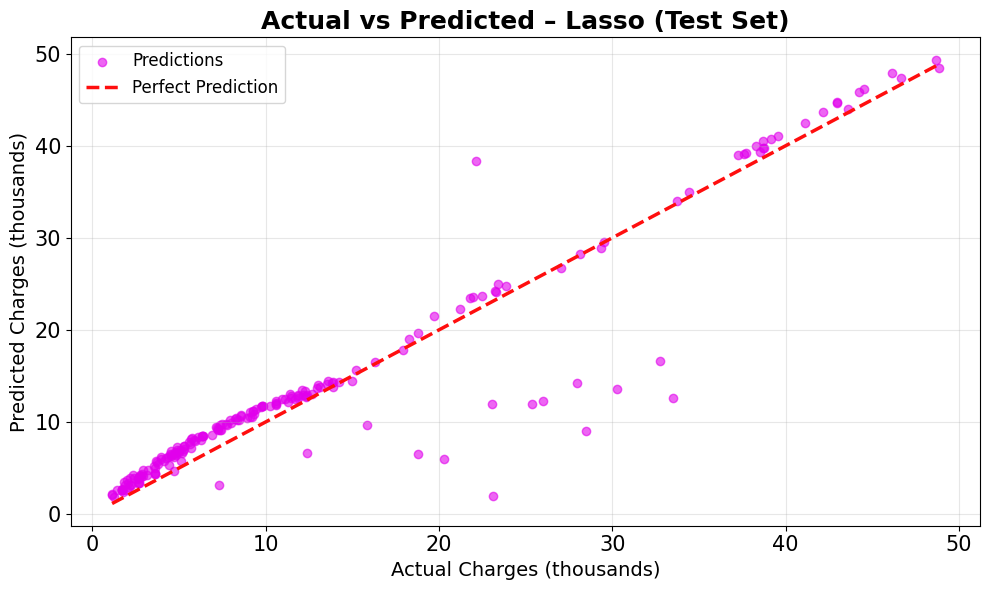

In [51]:
plt.figure(figsize=(10, 6))
plt.scatter(y_test_raw / 1000, pred / 1000, alpha=0.6, color="#e100ec", label='Predictions')
plt.plot([y_test_raw.min() / 1000, y_test_raw.max() / 1000], [y_test_raw.min() / 1000, y_test_raw.max() / 1000],
          '--', color='#ff0e0e', lw=2.5, label='Perfect Prediction')
plt.xlabel('Actual Charges (thousands)', fontsize=14); plt.ylabel('Predicted Charges (thousands)', fontsize=14)
plt.title(f'Actual vs Predicted – {best_name} (Test Set)', fontsize=18, fontweight='bold')
plt.xticks(fontsize=15); plt.yticks(fontsize=15); plt.legend(fontsize=12); plt.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(REG_DIR_FIG / "fig_reg_ins_ml_actual_vs_pred.png", dpi=300); plt.show()

#### - Residual plot

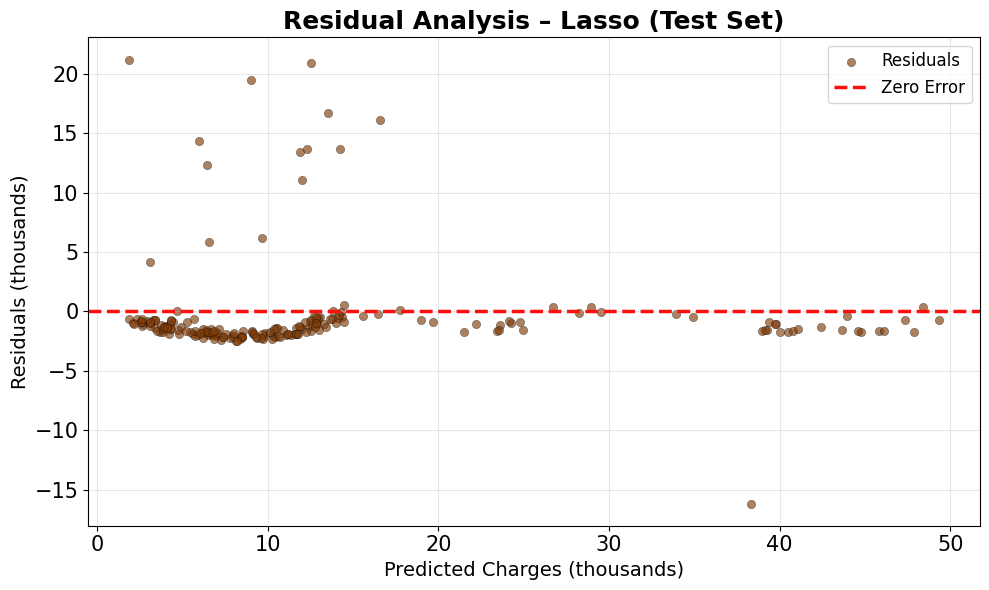

In [50]:
residuals = y_test_raw - pred
plt.figure(figsize=(10, 6))
plt.scatter(pred / 1000, residuals / 1000, alpha=0.65, edgecolor='black', linewidth=0.3, color="#803d09", label='Residuals')
plt.axhline(y=0, color='#ff0e0e', linestyle='--', linewidth=2.5, label='Zero Error')
plt.xlabel('Predicted Charges (thousands)', fontsize=14); plt.ylabel('Residuals (thousands)', fontsize=14)
plt.title(f'Residual Analysis – {best_name} (Test Set)', fontsize=18, fontweight='bold')
plt.xticks(fontsize=15); plt.yticks(fontsize=15); plt.grid(alpha=0.3); plt.legend(fontsize=12)
plt.tight_layout(); plt.savefig(REG_DIR_FIG / "fig_reg_ins_ml_residuals.png", dpi=300); plt.show()

#### - Coefficient (Feature) importance

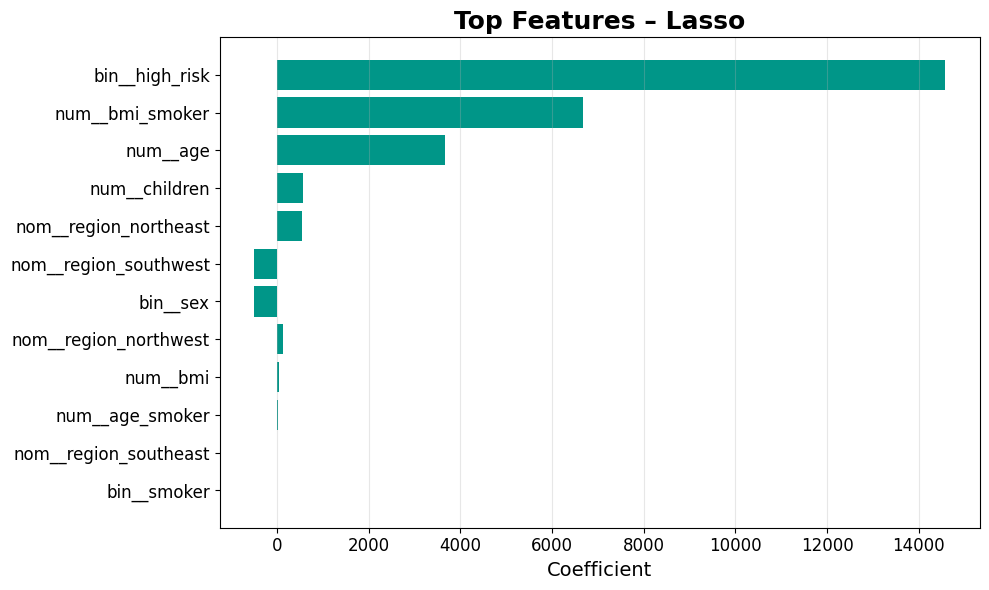

In [48]:
#--------------------------------------------------------
# Feature coefficients / importances of the final model + save
#--------------------------------------------------------
pipe_f = final_ml.regressor_ if LOG else final_ml
est_f, pre_f = pipe_f.named_steps["model"], pipe_f.named_steps["prep"]
vals = est_f.coef_ if hasattr(est_f, "coef_") else est_f.feature_importances_
lab = "Coefficient" if hasattr(est_f, "coef_") else "Importance"
imp = pd.DataFrame({"Feature": pre_f.get_feature_names_out(), lab: np.ravel(vals)})
imp["Abs"] = imp[lab].abs(); imp = imp.sort_values("Abs").tail(12)

plt.figure(figsize=(10, 6))
plt.barh(imp["Feature"], imp[lab], color="#009688")
plt.xlabel(lab, fontsize=14); plt.title(f"Top Features – {best_name}", fontsize=18, fontweight="bold")
plt.xticks(fontsize=12); plt.yticks(fontsize=12); plt.grid(axis="x", alpha=0.3)
plt.tight_layout(); plt.savefig(REG_DIR_FIG / "fig_reg_ins_ml_features.png", dpi=300); plt.show()



In [49]:
#--------------------------------------------
# Save the model & preprocessing pipeline
#--------------------------------------------

joblib.dump(final_ml, PROJECT_ROOT / "Models/Regression/ml_insurance_cost_model.joblib")


['F:\\Desktop\\Projects\\AI-ML-DL\\Medical-Healthcare-Prediction-Framework\\Models\\Regression\\ml_insurance_cost_model.joblib']